### Exploratory data analysis 

- **Part-1: Data overview**
    > check the #samples, #attributes <br>
    > attribute types <br>
    
- **Part-2: Data cleaning**
    > organize attributes into appripriate data types (e.g., numerical, categorical) <br>
    > missing value and outlier detection <br>
    
- **Part-3: Data transformation**
    > explore target variable <br>
    > normalize numerical data <br>
    
- **Part-4: Feature engineering**
    > encode categorical data <br>

- **Part-5: Additional analysis**
    > colinearty check <br>


In [475]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Data overview

In [476]:
# read data from file to a pandas dataframe
df = pd.read_csv('./customer_data.csv') 

In [477]:
# check the shape of the data frame: row: #samples, column: #attributes 
df.shape

(100000, 12)

We can see that there are 100000 samples and 12 attributes.

In [478]:
# get an overview of the top 20 rows/samples
df.head(20)

,id,age,gender,income,education,region,loyalty_status,purchase_frequency,purchase_amount,product_category,promotion_usage,satisfaction_score
0,1,27,Male,40682,Bachelor,East,Gold,frequent,18249,Books,0,6
1,2,29,Male,15317,Masters,West,Regular,rare,4557,Clothing,1,6
2,3,37,Male,38849,Bachelor,West,Silver,rare,11822,Clothing,0,6
3,4,30,Male,11568,HighSchool,South,Regular,frequent,4098,Food,0,7
4,5,31,Female,46952,College,North,Regular,occasional,19685,Clothing,1,5
5,6,38,Male,7347,Bachelor,South,Silver,occasional,2822,Electronics,0,5
6,7,32,Female,8265,Bachelor,South,Silver,frequent,3293,Clothing,0,7
7,8,24,Female,47773,HighSchool,North,Regular,rare,21794,Books,0,5
8,9,27,Male,19154,College,East,Regular,occasional,5819,Clothing,0,5
9,10,28,Female,24666,HighSchool,North,Regular,rare,8779,Food,0,6


### Data cleaning

In [479]:
# Check if there is any missing value
null_sum = df.isnull().sum()
null_sum

id                    0
age                   0
gender                0
income                0
education             0
region                0
loyalty_status        0
purchase_frequency    0
purchase_amount       0
product_category      0
promotion_usage       0
satisfaction_score    0
dtype: int64

In [480]:
# Check the data types
df.dtypes 

id                     int64
age                    int64
gender                object
income                 int64
education             object
region                object
loyalty_status        object
purchase_frequency    object
purchase_amount        int64
product_category      object
promotion_usage        int64
satisfaction_score     int64
dtype: object

#### organize columns into different data types
The .dtype attribute shows that the current data type for numerical data is "int", and data type for numerical data is "object".   

We will organize the columns into the following common data types based on the observation (decide the data type based on its values):
- Categorical: 
    > id, gender,region, loyalty_status,purchase_frequency,purchase_amount,product_category,promotion_usage,satisfaction_score <br>
- Numerical: 
    > income,purchase_amount <br>

In the following part, we will: 
- convert the original data into the organized data type 
- do data processing for the converted data

#### process categorical data

In [481]:
# Convert the following columns to categorical data types 
cat_col = ['id', 'gender', 'education', 'region', 'loyalty_status', 'product_category', 'promotion_usage', 'purchase_frequency']
df[cat_col] = df[cat_col].astype('category')
df[cat_col]

,id,gender,education,region,loyalty_status,product_category,promotion_usage,purchase_frequency
0,1,Male,Bachelor,East,Gold,Books,0,frequent
1,2,Male,Masters,West,Regular,Clothing,1,rare
2,3,Male,Bachelor,West,Silver,Clothing,0,rare
3,4,Male,HighSchool,South,Regular,Food,0,frequent
4,5,Female,College,North,Regular,Clothing,1,occasional
...,...,...,...,...,...,...,...,...
99995,99996,Female,College,West,Regular,Health,0,occasional
99996,99997,Male,HighSchool,South,Regular,Health,0,rare
99997,99998,Male,College,West,Regular,Clothing,0,frequent
99998,99999,Female,Bachelor,West,Regular,Health,1,frequent


In [482]:
# the category columns now all have the categorical data types
df[cat_col].dtypes

id                    category
gender                category
education             category
region                category
loyalty_status        category
product_category      category
promotion_usage       category
purchase_frequency    category
dtype: object

**check outliers of each categorical feature**

In [483]:
df['gender'].value_counts() 

gender
Female    50074
Male      49926
Name: count, dtype: int64

In [484]:
df['education'].value_counts() 

education
College       39874
Bachelor      30279
HighSchool    20031
Masters        9816
Name: count, dtype: int64

In [485]:
df['region'].value_counts() 

region
East     30074
West     29935
South    20073
North    19918
Name: count, dtype: int64

In [486]:
df['loyalty_status'].value_counts() 

loyalty_status
Regular    60138
Silver     29964
Gold        9898
Name: count, dtype: int64

In [487]:
df['product_category'].value_counts() 

product_category
Electronics    30027
Clothing       19989
Books          14925
Food           14822
Health         10123
Home            5079
Beauty          5035
Name: count, dtype: int64

In [488]:
df['promotion_usage'].value_counts() 

promotion_usage
0    69920
1    30080
Name: count, dtype: int64

In [489]:
df['purchase_frequency'].value_counts() 

purchase_frequency
rare          50019
occasional    29886
frequent      20095
Name: count, dtype: int64

We can see that for categorical data, there is no obvious outliners to be dropped. Also, they're basically reasonably distributed. For this moment, we're considering further encode the categorical data based on their current categories. But for loyalty_status and purchase_frequency, we may consider convert them into binary variables.

#### process numerical data

In [490]:
#create numerical columns
num_col = ['income','purchase_amount']

In [491]:
# for future transformation,float
df[num_col] = df[num_col].astype('float')
df[num_col].dtypes

income             float64
purchase_amount    float64
dtype: object

In [492]:
# descriptive statistics for the numerical columns
df[num_col].describe()

,income,purchase_amount
count,100000.000000,100000.000000
mean,27516.269880,9634.790840
std,12996.782587,4799.339449
min,5000.000000,1118.000000
25%,16271.750000,5583.000000
50%,27584.500000,9452.000000
75%,38747.250000,13350.000000
max,50000.000000,26204.000000


##### for 'income'

<Axes: xlabel='income'>

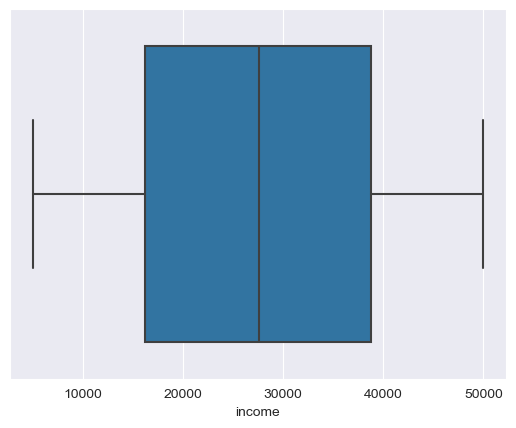

In [493]:
# draw box plot to check outliers
sns.set_style("darkgrid",{'axes.grid' : True})
sns.boxplot(x=df['income'], orient='h')

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


<Axes: xlabel='income', ylabel='Count'>

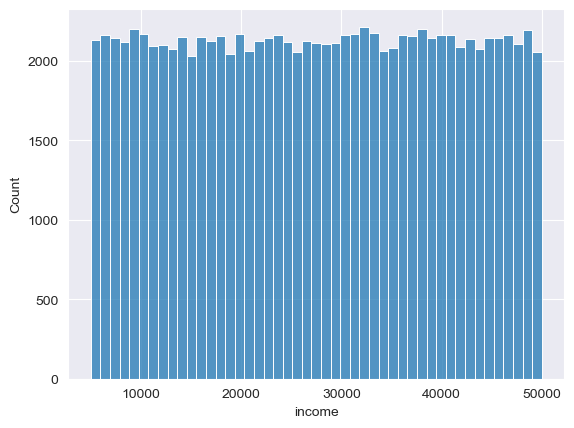

In [494]:
sns.histplot(df['income'])

In [495]:
Q1 = df['income'].quantile(0.25)
Q3 = df['income'].quantile(0.75)
IQR = Q3 - Q1
lower_thresh = Q1 - 1.5*IQR
upper_thresh = Q3 + 1.5*IQR
Q1, Q3, lower_thresh, upper_thresh

(16271.75, 38747.25, -17441.5, 72460.5)

##### for 'purchase_amount'

<Axes: xlabel='purchase_amount'>

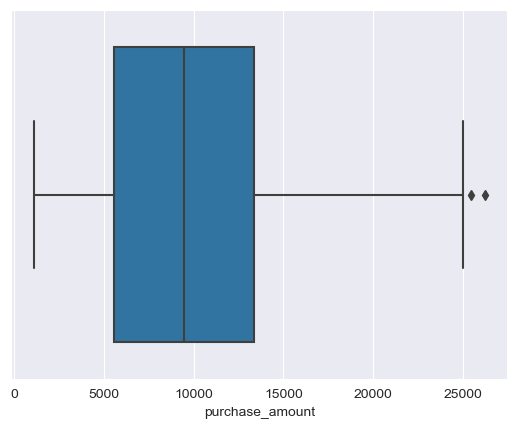

In [496]:
# draw box plot to check outliers
sns.set_style("darkgrid",{'axes.grid' : True})
sns.boxplot(x=df['purchase_amount'], orient='h')

In [497]:
Q1 = df['purchase_amount'].quantile(0.25)
Q3 = df['purchase_amount'].quantile(0.75)
IQR = Q3 - Q1
lower_thresh = Q1 - 1.5*IQR
upper_thresh = Q3 + 1.5*IQR
Q1, Q3, lower_thresh, upper_thresh

(5583.0, 13350.0, -6067.5, 25000.5)

In [499]:
df['purchase_amount'].min( )
df['purchase_amount'].max( )

26204.0

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


<Axes: xlabel='purchase_amount', ylabel='Count'>

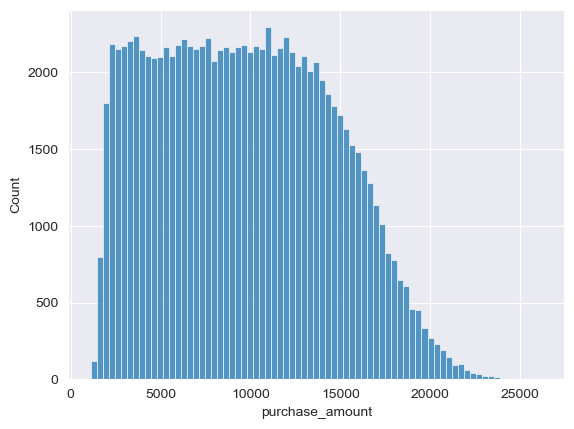

In [500]:
sns.histplot(df['purchase_amount'])

In [501]:
# Based on the above calculation, we will remove samples that have "purchase_amount" above 21000 (>21000) as outliers 
# since they‘re extremely high
df.drop(df[df['purchase_amount'] > 21000].index, inplace=True)
df.shape

(99523, 12)

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


<Axes: xlabel='purchase_amount', ylabel='Count'>

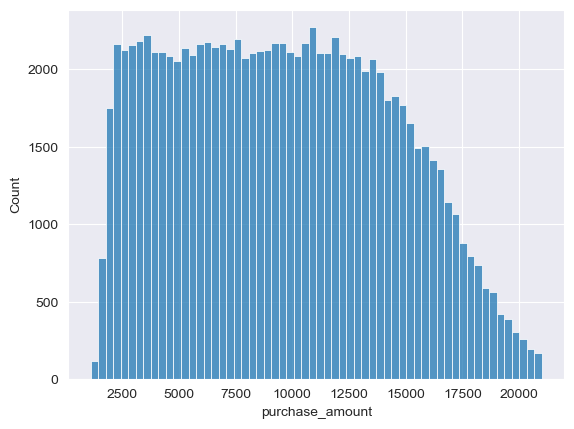

In [502]:
# check the current distribution
sns.histplot(df['purchase_amount'])

### Data transformation
In this part, we will move forward to do data transformation mainly for target variable and numerical data.

#### Transform Target Variable

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


<Axes: xlabel='satisfaction_score', ylabel='Count'>

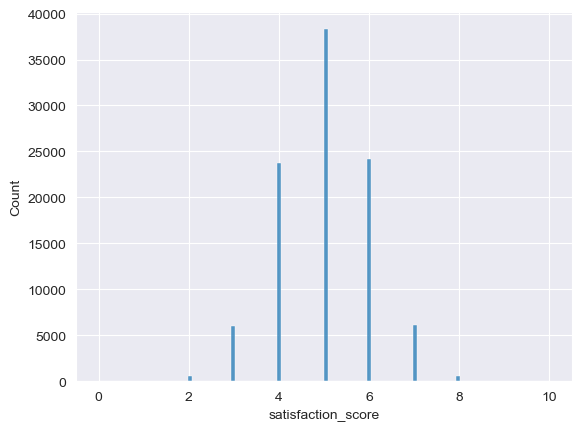

In [508]:
sns.histplot(df['satisfaction_score'])

In [516]:
# We took 5 as a thershold, when satisfaction_score>5, it's considered as satisfied, when <5 it's considered as unsatisfied
def categorize_satisfaction(score):
    if df['satisfaction_score'].all() < 5:
        return 'not satisfied'
    else:
        return 'satisfied'
        
df['satisfaction_category'] = df[['satisfaction_score']].apply(categorize_satisfaction)
df['satisfaction_category'].head()

TypeError: categorize_satisfaction() takes 0 positional arguments but 1 was given

#### Normalize numerical data

#####  Normalize “income”

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


<Axes: xlabel='income', ylabel='Count'>

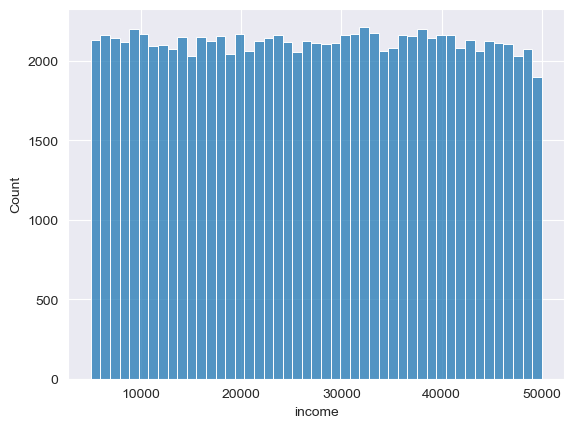

In [347]:
# check the distribution of the "income" before normalization
sns.histplot(df['income'])

In [348]:
# normalize income
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler(feature_range=(0,1))
df['income'] = scaler.fit_transform(df[['income']].values)

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


<Axes: xlabel='income', ylabel='Count'>

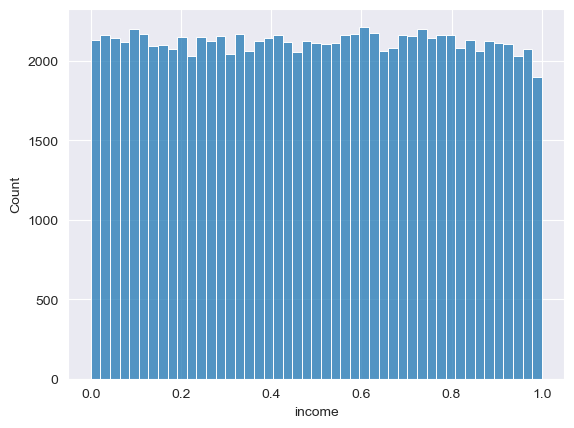

In [349]:
# check the distribution of the "income" after normalization
sns.histplot(df['income'] )

##### Normalize “purchase_amount”

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


<Axes: xlabel='purchase_amount', ylabel='Count'>

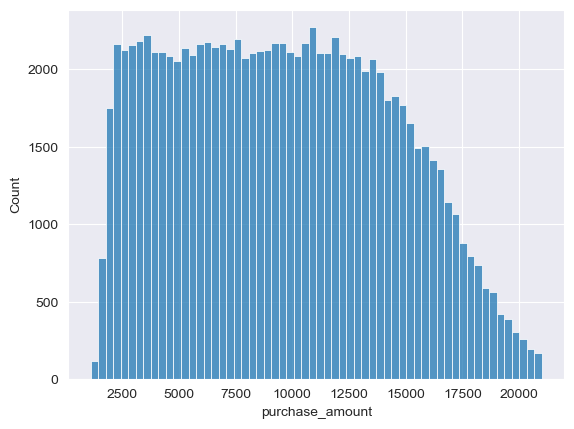

In [350]:
# check the distribution of the "purchase_amount" before normalization
sns.histplot(df['purchase_amount'])

In [351]:
# normalize income
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler(feature_range=(0,1))
df['purchase_amount'] = scaler.fit_transform(df[['purchase_amount']].values)

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


<Axes: xlabel='purchase_amount', ylabel='Count'>

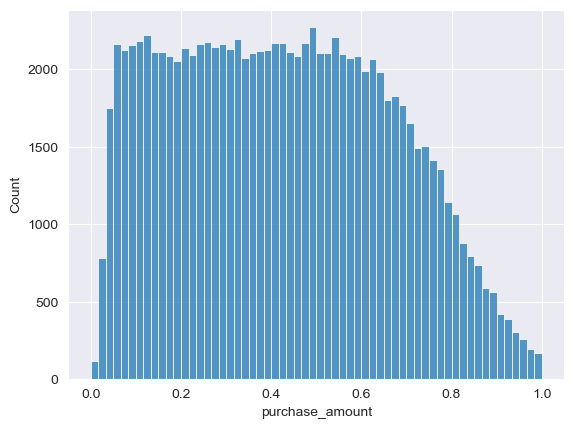

In [352]:
# check the distribution of the "purchase amount" after normalization
sns.histplot(df['purchase_amount'] )

We can see that normalization doesn't change the distribution.

### Feature Engineering

#### Numerical data
- directly use the values

#### Categorical data
- encoding (one-hot/ordinal encoder)

In [452]:
from sklearn.preprocessing import OneHotEncoder

In [503]:
ohe = OneHotEncoder(handle_unknown='ignore', dtype = np.int64)

##### for ‘gender’

In [504]:
# Initiate one-hot encoder
ohe.fit(df[['gender']])

OneHotEncoder(dtype=<class 'numpy.int64'>, handle_unknown='ignore')

In [505]:
# the categories learned during the fit process
ohe.categories_ 

[array(['Female', 'Male'], dtype=object)]

In [506]:
# encode the "gender" with the learned categories during the fit process
ohe.transform(df[['gender']]).toarray()

array([[0, 1],
       [0, 1],
       [0, 1],
       ...,
       [0, 1],
       [1, 0],
       [1, 0]])

In [507]:
df_gender = pd.DataFrame(ohe.transform(df[['gender']]).toarray(),columns=ohe.categories_)

##### for ‘region'

In [359]:
# Initiate one-hot encoder
ohe.fit(df[['region']])

OneHotEncoder(handle_unknown='ignore')

In [360]:
# the categories learned during the fit process
ohe.categories_

[array(['East', 'North', 'South', 'West'], dtype=object)]

In [361]:
# encode the "region" with the learned categories during the fit process
ohe.transform(df[['region']]).toarray()

array([[1., 0., 0., 0.],
       [0., 0., 0., 1.],
       [0., 0., 0., 1.],
       ...,
       [0., 0., 0., 1.],
       [0., 0., 0., 1.],
       [0., 0., 0., 1.]])

In [362]:
pd.DataFrame(ohe.transform(df[['region']]).toarray().astype(int),columns=ohe.categories_)

,East,North,South,West
0,1,0,0,0
1,0,0,0,1
2,0,0,0,1
3,0,0,1,0
4,0,1,0,0
...,...,...,...,...
99518,0,0,0,1
99519,0,0,1,0
99520,0,0,0,1
99521,0,0,0,1


##### for ‘education'

In [363]:
# Initiate one-hot encoder
ohe.fit(df[['education']])

OneHotEncoder(handle_unknown='ignore')

In [364]:
# the categories learned during the fit process
ohe.categories_

[array(['Bachelor', 'College', 'HighSchool', 'Masters'], dtype=object)]

In [365]:
# encode the "education" with the learned categories during the fit process
ohe.transform(df[['education']]).toarray()

array([[1., 0., 0., 0.],
       [0., 0., 0., 1.],
       [1., 0., 0., 0.],
       ...,
       [0., 1., 0., 0.],
       [1., 0., 0., 0.],
       [0., 1., 0., 0.]])

In [366]:
pd.DataFrame(ohe.transform(df[['education']]).toarray().astype(int),columns=ohe.categories_)

,Bachelor,College,HighSchool,Masters
0,1,0,0,0
1,0,0,0,1
2,1,0,0,0
3,0,0,1,0
4,0,1,0,0
...,...,...,...,...
99518,0,1,0,0
99519,0,0,1,0
99520,0,1,0,0
99521,1,0,0,0


##### for ‘loyalty_status’

In [367]:
# Initiate one-hot encoder
ohe.fit(df[['loyalty_status']])

OneHotEncoder(handle_unknown='ignore')

In [368]:
# the categories learned during the fit process
ohe.categories_

[array(['Gold', 'Regular', 'Silver'], dtype=object)]

In [369]:
# encode the "product_category" with the learned categories during the fit process
ohe.transform(df[['loyalty_status']]).toarray()

array([[1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.],
       ...,
       [0., 1., 0.],
       [0., 1., 0.],
       [0., 0., 1.]])

In [370]:
pd.DataFrame(ohe.transform(df[['loyalty_status']]).toarray().astype(int),columns=ohe.categories_)

,Gold,Regular,Silver
0,1,0,0
1,0,1,0
2,0,0,1
3,0,1,0
4,0,1,0
...,...,...,...
99518,0,1,0
99519,0,1,0
99520,0,1,0
99521,0,1,0


##### for ‘product_category'

In [371]:
# Initiate one-hot encoder
ohe.fit(df[['product_category']])

OneHotEncoder(handle_unknown='ignore')

In [372]:
# the categories learned during the fit process
ohe.categories_

[array(['Beauty', 'Books', 'Clothing', 'Electronics', 'Food', 'Health',
        'Home'], dtype=object)]

In [373]:
# encode the "product_category" with the learned categories during the fit process
ohe.transform(df[['product_category']]).toarray()

array([[0., 1., 0., ..., 0., 0., 0.],
       [0., 0., 1., ..., 0., 0., 0.],
       [0., 0., 1., ..., 0., 0., 0.],
       ...,
       [0., 0., 1., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 1., 0.],
       [0., 0., 0., ..., 0., 1., 0.]])

In [374]:
pd.DataFrame(ohe.transform(df[['product_category']]).toarray().astype(int),columns=ohe.categories_)

,Beauty,Books,Clothing,Electronics,Food,Health,Home
0,0,1,0,0,0,0,0
1,0,0,1,0,0,0,0
2,0,0,1,0,0,0,0
3,0,0,0,0,1,0,0
4,0,0,1,0,0,0,0
...,...,...,...,...,...,...,...
99518,0,0,0,0,0,1,0
99519,0,0,0,0,0,1,0
99520,0,0,1,0,0,0,0
99521,0,0,0,0,0,1,0


##### for ‘promotion_usage'

In [375]:
# Initiate one-hot encoder
ohe.fit(df[['promotion_usage']])

OneHotEncoder(handle_unknown='ignore')

In [376]:
# the categories learned during the fit process
ohe.categories_

[array([0, 1])]

In [377]:
# encode the "promotion_usage" with the learned categories during the fit process
ohe.transform(df[['promotion_usage']]).toarray()

array([[1., 0.],
       [0., 1.],
       [1., 0.],
       ...,
       [1., 0.],
       [0., 1.],
       [1., 0.]])

In [378]:
pd.DataFrame(ohe.transform(df[['promotion_usage']]).toarray().astype(int),columns=ohe.categories_)

,0,1
0,1,0
1,0,1
2,1,0
3,1,0
4,0,1
...,...,...
99518,1,0
99519,1,0
99520,1,0
99521,0,1


In [379]:
# rename the columns
pd.DataFrame(ohe.transform(df[['promotion_usage']]).toarray().astype(int), columns=ohe.categories_).rename(columns={0: 'no', 1: 'yes'})

,no,yes
0,1,0
1,0,1
2,1,0
3,1,0
4,0,1
...,...,...
99518,1,0
99519,1,0
99520,1,0
99521,0,1


##### for ‘purchase_frequency'

In [405]:
# Initiate one-hot encoder
ohe.fit(df[['purchase_frequency']])

OneHotEncoder(handle_unknown='ignore')

In [406]:
# the categories learned during the fit process
ohe.categories_

[array(['frequent', 'occasional', 'rare'], dtype=object)]

In [407]:
# encode the "promotion_usage" with the learned categories during the fit process
ohe.transform(df[['purchase_frequency']]).toarray()

array([[1., 0., 0.],
       [0., 0., 1.],
       [0., 0., 1.],
       ...,
       [1., 0., 0.],
       [1., 0., 0.],
       [0., 0., 1.]])

In [408]:
pd.DataFrame(ohe.transform(df[['purchase_frequency']]).toarray().astype(int),columns=ohe.categories_)

,frequent,occasional,rare
0,1,0,0
1,0,0,1
2,0,0,1
3,1,0,0
4,0,1,0
...,...,...,...
99518,0,1,0
99519,0,0,1
99520,1,0,0
99521,1,0,0


### Additional Analysis

#### Check the colinearity

In [384]:
# set the size of the heatmap.
plt.figure(figsize=(11, 11))

# Create the heatmap using Seaborn and adjust the font size of annotations
heatmap = sns.heatmap(df[A].corr(), vmin=-1, vmax=1, cmap='BrBG',annot=True)

# Set the title
heatmap.set_title('Correlation Heatmap', fontdict={'fontsize':30}, pad=14);

<Figure size 2000x1000 with 0 Axes>

<Figure size 2000x1000 with 0 Axes>

KeyError: "['Male'] not in index"